In [1]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.decomposition import PCA


sys.path.append(os.path.join(os.getcwd(), '../../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../../'))
from utils import plot_utils
from utils import train_utils

In [2]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/exploration/heatmaps/../../../../../utils/train_utils.py'>

In [3]:
dims = 3

read_ids = list(range(0, 9+1))
# read_ids = [0,	# paper
# 			1,	# nice states
# 			2,	# nice manifold
# 			5,	# variety
# 			6,	# nice quiescence
# 			7,	# nice states
# 			9,	# nice heatmap
# 			11]	# variety
# read_ids = [0]
plot_ids = read_ids

In [4]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain/incomplete/no_pickle/flailing')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids, with_markers=False)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [5]:
# prep

def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

In [6]:
plot_idxs = [file_ids.index(plot_id) for plot_id in plot_ids]

# states = [ds[selection_bhl] for ds in states]

In [7]:
(modes_manifold,
 recos_manifold,
 loads_pca_man,
 vars_expl_mans) = train_utils.get_manifolds_pca(traces, zscore=False,
												 n_pc=dims)

In [8]:
traces_manifolds_indices = [np.argsort(xloads_pca_man[0, :])[::-1] for xloads_pca_man in loads_pca_man]

traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]

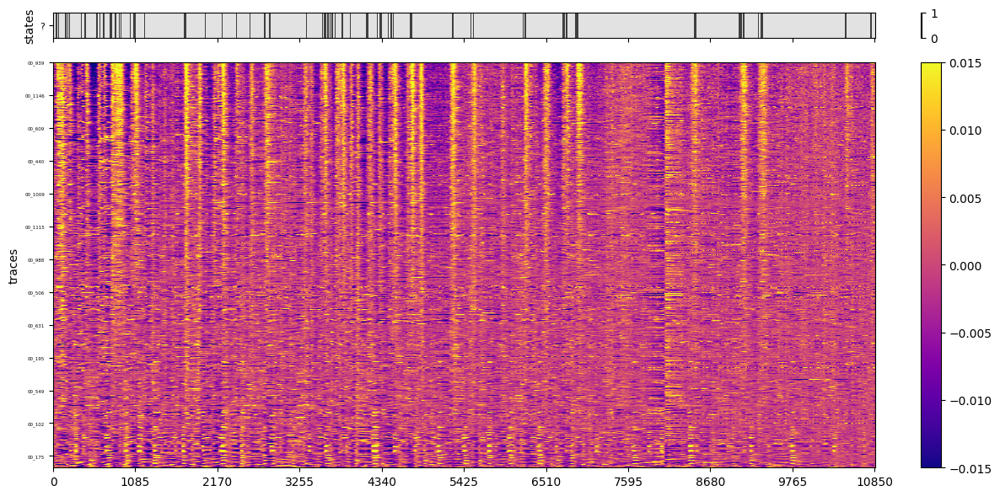

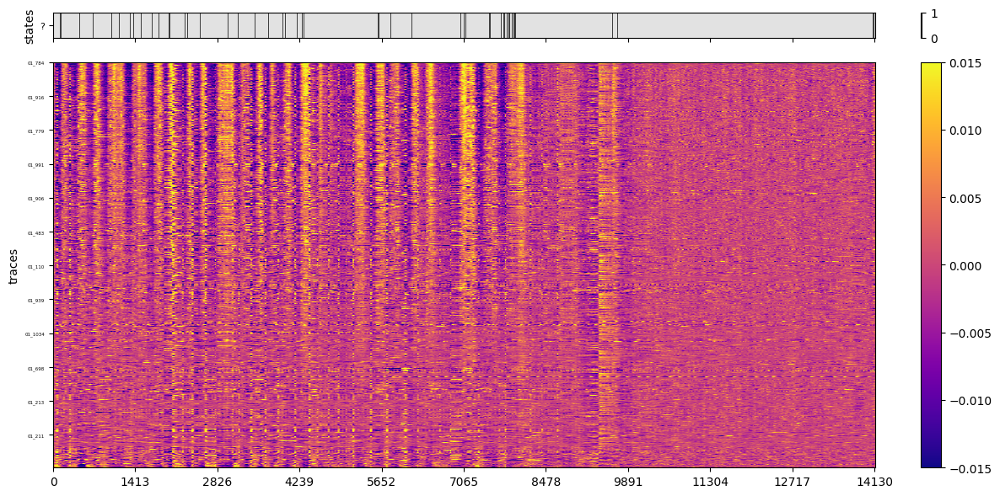

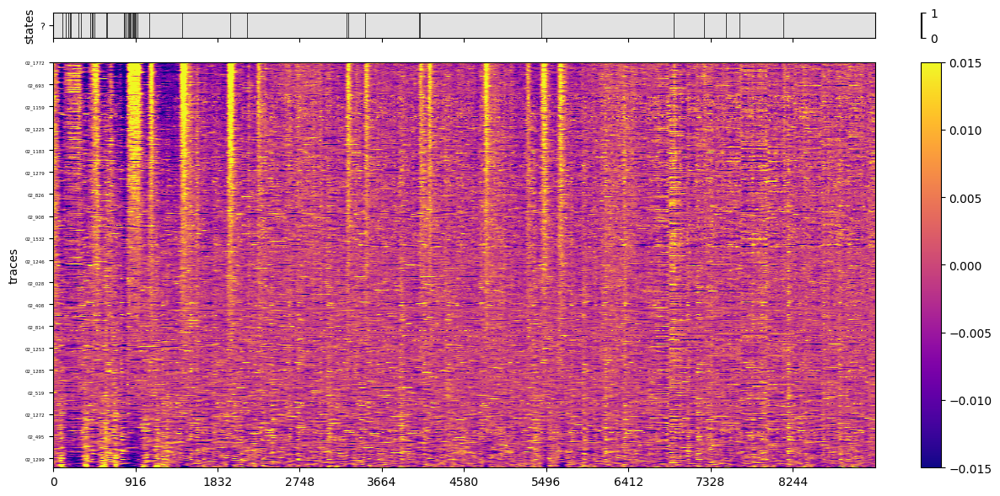

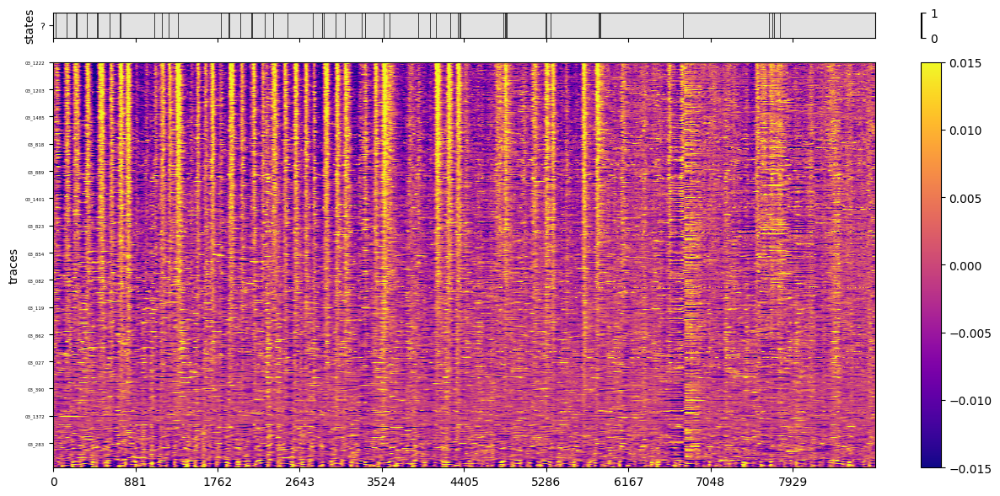

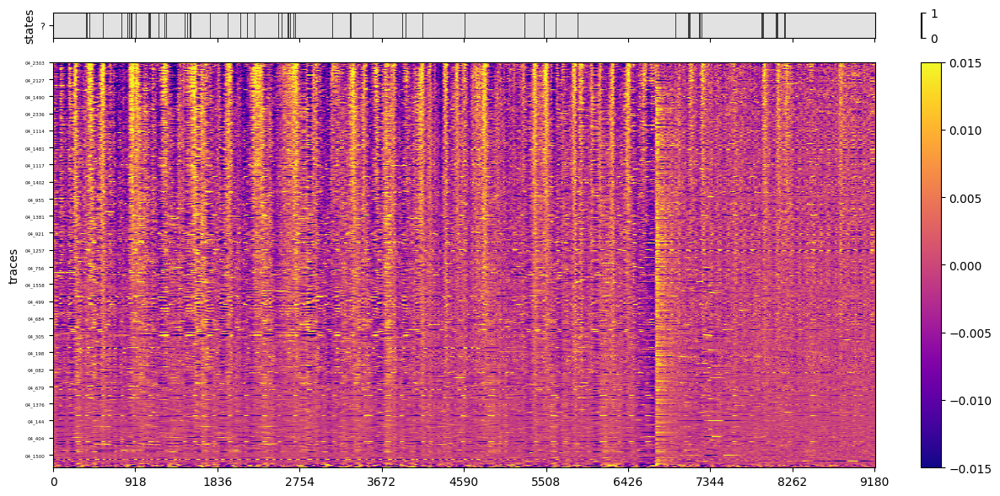

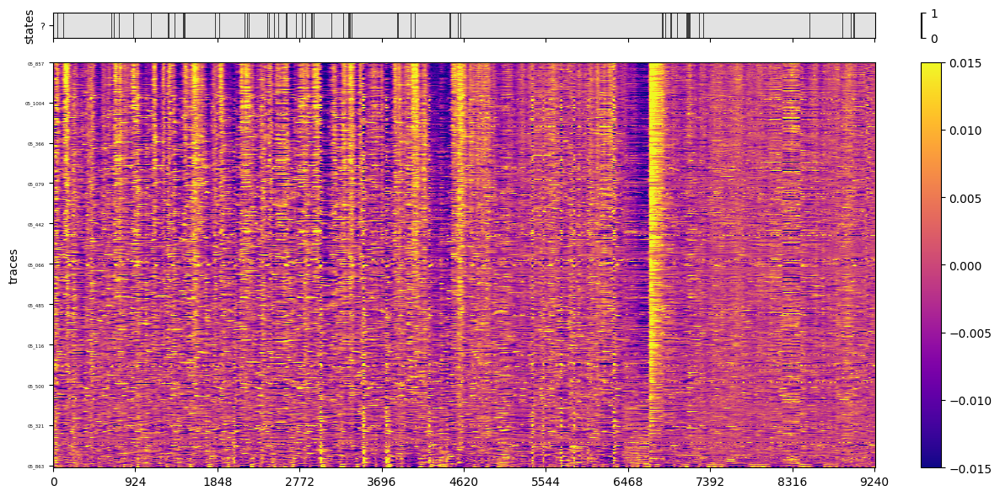

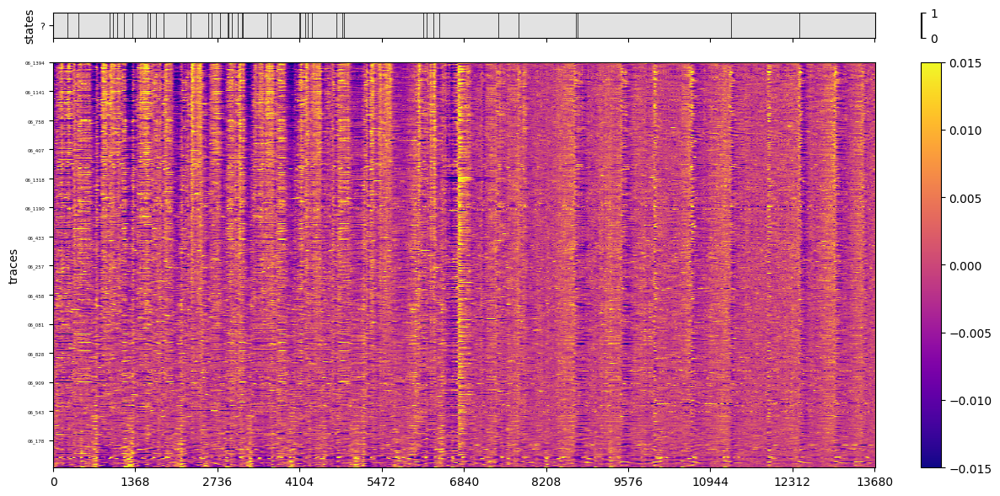

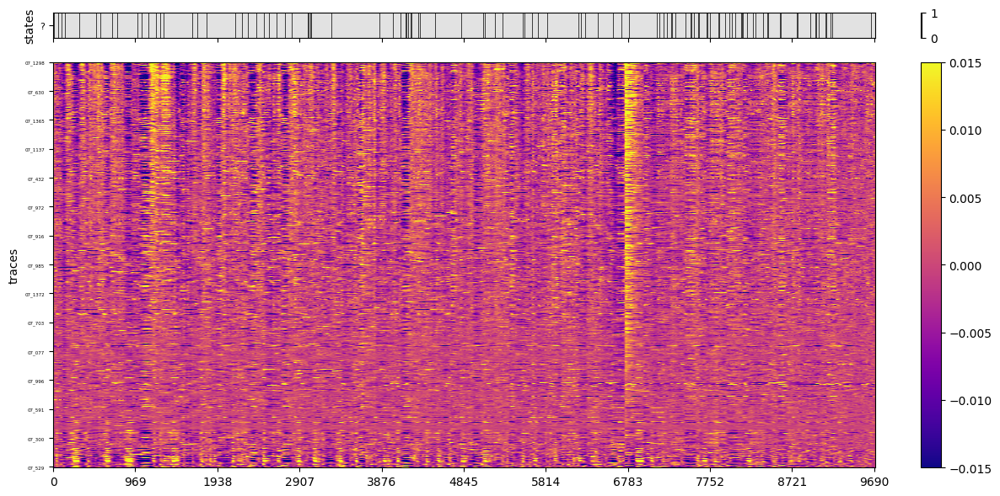

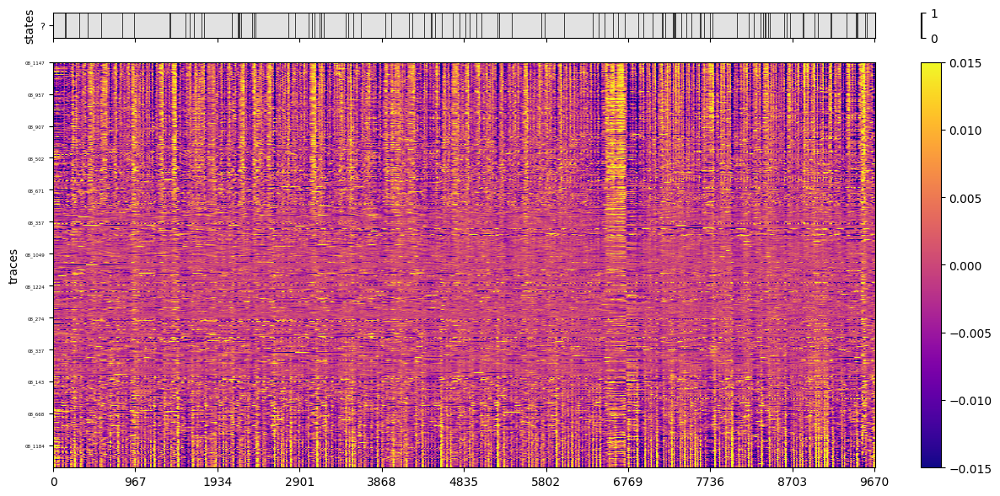

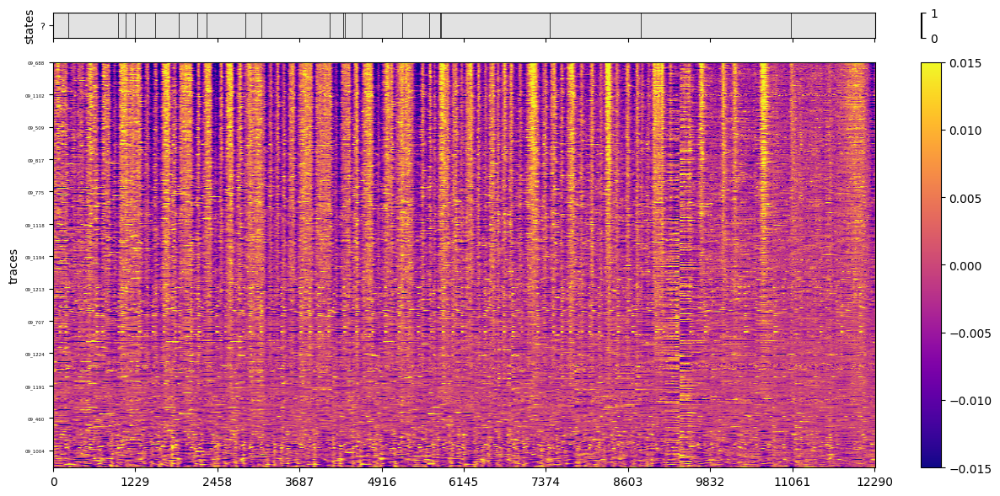

In [9]:
save_heatmaps = True

for plot_idx in plot_idxs:
	plot_utils.plot_heatmap_stack(
		traces_sorted[plot_idx],
		states[plot_idx],
		'traces', 'states',
		zlimits_activity=(-0.015, 0.015), cmap='plasma', neuron_ids=False, height_ratios=(1, 16),
		save_path=f'../../../out/plots/heatmaps/flailing/hpf/{filenames[plot_idx]}' if save_heatmaps else None)